# Breast Cancer Diagnostic Machine Learning Project

## Project overview

This project explores whether measurements of cell nuclei from digitised fine-needle aspirate samples can help distinguish benign from malignant breast masses. It uses the [Wisconsin Diagnostic Breast Cancer dataset on Kaggle](https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data), which contains 569 samples and 30 numerical features. The target is the recorded diagnosis: benign or malignant. [UCI dataset description](https://archive.ics.uci.edu/dataset/17/breast%2Bcancer%2Bwisconsin%2Bdiagnostic)


## Aims

- Explore the diagnosis balance and how the measured features vary.
- Build a simple majority-class baseline.
- Compare the baseline with logistic regression.
- Compare and contrast different thresholds to evaluate increass in accuracy and explore varying false positive/negative results.
- Determine the strongest threshold (based of this limited model) for different real world situations.

## Testing and evaluation

Reserve a stratified 20% of the labelled data as a final holdout set. Use only the remaining training data to develop and compare models; keep the holdout untouched until the final evaluation. Fit scaling within the model pipeline to avoid using information from the holdout during training.

Report accuracy, malignant-case recall, precision, F1, ROC-AUC, and a confusion matrix. Malignant recall deserves particular attention because it shows how many malignant cases the model identifies.

## Success criteria and limitations

A successful project will produce a reproducible notebook, compare model performance against the baseline, and clearly explain how different thresholds would inform diagnosis and suggest a possible strongest threshold for this particular model. 

#### **Caveat:** This project is for learning and development not the actual creation of a tool used to assess real-world patients

## Methodology

### **Step 1** - Project set up

In [ ]:
%pip install numpy pandas scikit-learn matplotlib seaborn ipykernel

In [7]:
# Standard library
from pathlib import Path

# Data handling and notebook display
import numpy as np
import pandas as pd
from IPython.display import display

# Graphics
import matplotlib.pyplot as plt
import seaborn as sns

# Data splitting and model pipelines
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

# Model evaluation and plots
from sklearn.metrics import (
    accuracy_score,
    auc,
    classification_report,
    confusion_matrix,
    recall_score,
    roc_auc_score,
    roc_curve,
)

In [3]:
# Load the full dataset from the project folder

data_file = Path("Data") / "cancer_diagnosis_dataset.csv"
df = pd.read_csv(data_file)

print("Loaded shape:", df.shape)  # Expected: (569, 32)
print("Loaded from:", data_file.resolve())

# Display the first five rows
from IPython.display import display

pd.set_option("display.max_columns", None)
display(df.head())

Loaded shape: (569, 32)
Loaded from: C:\Users\Admin\OneDrive\Documents\2_CPD\4_Portfolio Stuff\Portfolio Projects\6_Breast Cancer Diagnostics\Python\Data\cancer_diagnosis_dataset.csv


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave_points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


### **Step 2** - Build and train model

In [ ]:
# Seperating full dataset into testing dataset (X) and result testing against (y)

X = df.drop(columns=["id", "diagnosis"])
y = df["diagnosis"].map({"B": 0, "M": 1})

print("Input features:", X.shape[1])  # Should be 30 after removing unhelpful and result columns

Input features: 30


In [15]:
# Hold out the test data
X_train_validation, X_test, y_train_validation, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

# Split the remaining data into training and validation sets
X_train, X_validation, y_train, y_validation = train_test_split(
    X_train_validation,
    y_train_validation,
    test_size=0.25,
    random_state=42,
    stratify=y_train_validation,
)


# 1. Define models separately
baseline_model = DummyClassifier(strategy="most_frequent")
logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)


# 2. Fit/train each model on training data
baseline_model.fit(X_train, y_train)
logistic_model.fit(X_train, y_train)

# 3. Generate predictions on test data
baseline_preds = baseline_model.predict(X_test)
logistic_preds = logistic_model.predict(X_test)

# 4. Evaluate and compare performance
print("Baseline Accuracy:", accuracy_score(y_test, baseline_preds))
print("Logistic Regression Accuracy:", accuracy_score(y_test, logistic_preds))




Baseline Accuracy: 0.631578947368421
Logistic Regression Accuracy: 0.9736842105263158


In [16]:
# Get malignant probabilities for the validation data
validation_probabilities = logistic_model.predict_proba(X_validation)[:, 1]

# Store the results for each threshold
threshold_results = []

# Evaluate the 0.50 threshold
threshold_050 = 0.50
predictions_050 = (validation_probabilities >= threshold_050).astype(int)
tn_050, fp_050, fn_050, tp_050 = confusion_matrix(
    y_validation, predictions_050, labels=[0, 1]
).ravel()

threshold_results.append({
    "Threshold": threshold_050,
    "Accuracy (%)": accuracy_score(y_validation, predictions_050) * 100,
    "Malignant recall (%)": recall_score(y_validation, predictions_050) * 100,
    "False positive rate (%)": fp_050 / (fp_050 + tn_050) * 100,
    "False negative rate (%)": fn_050 / (fn_050 + tp_050) * 100,
    "False positives": fp_050,
    "False negatives": fn_050
})

# Evaluate the 0.40 threshold
threshold_040 = 0.40
predictions_040 = (validation_probabilities >= threshold_040).astype(int)
tn_040, fp_040, fn_040, tp_040 = confusion_matrix(
    y_validation, predictions_040, labels=[0, 1]
).ravel()

threshold_results.append({
    "Threshold": threshold_040,
    "Accuracy (%)": accuracy_score(y_validation, predictions_040) * 100,
    "Malignant recall (%)": recall_score(y_validation, predictions_040) * 100,
    "False positive rate (%)": fp_040 / (fp_040 + tn_040) * 100,
    "False negative rate (%)": fn_040 / (fn_040 + tp_040) * 100,
    "False positives": fp_040,
    "False negatives": fn_040
})

# Evaluate the 0.30 threshold
threshold_030 = 0.30
predictions_030 = (validation_probabilities >= threshold_030).astype(int)
tn_030, fp_030, fn_030, tp_030 = confusion_matrix(
    y_validation, predictions_030, labels=[0, 1]
).ravel()

threshold_results.append({
    "Threshold": threshold_030,
    "Accuracy (%)": accuracy_score(y_validation, predictions_030) * 100,
    "Malignant recall (%)": recall_score(y_validation, predictions_030) * 100,
    "False positive rate (%)": fp_030 / (fp_030 + tn_030) * 100,
    "False negative rate (%)": fn_030 / (fn_030 + tp_030) * 100,
    "False positives": fp_030,
    "False negatives": fn_030
})

# Evaluate the 0.20 threshold
threshold_020 = 0.20
predictions_020 = (validation_probabilities >= threshold_020).astype(int)
tn_020, fp_020, fn_020, tp_020 = confusion_matrix(
    y_validation, predictions_020, labels=[0, 1]
).ravel()

threshold_results.append({
    "Threshold": threshold_020,
    "Accuracy (%)": accuracy_score(y_validation, predictions_020) * 100,
    "Malignant recall (%)": recall_score(y_validation, predictions_020) * 100,
    "False positive rate (%)": fp_020 / (fp_020 + tn_020) * 100,
    "False negative rate (%)": fn_020 / (fn_020 + tp_020) * 100,
    "False positives": fp_020,
    "False negatives": fn_020
})

# Evaluate the 0.10 threshold
threshold_010 = 0.10
predictions_010 = (validation_probabilities >= threshold_010).astype(int)
tn_010, fp_010, fn_010, tp_010 = confusion_matrix(
    y_validation, predictions_010, labels=[0, 1]
).ravel()

threshold_results.append({
    "Threshold": threshold_010,
    "Accuracy (%)": accuracy_score(y_validation, predictions_010) * 100,
    "Malignant recall (%)": recall_score(y_validation, predictions_010) * 100,
    "False positive rate (%)": fp_010 / (fp_010 + tn_010) * 100,
    "False negative rate (%)": fn_010 / (fn_010 + tp_010) * 100,
    "False positives": fp_010,
    "False negatives": fn_010
})

# Compare all validation results in one table
threshold_comparison = pd.DataFrame(threshold_results)
display(threshold_comparison.round(1))

,Threshold,Accuracy (%),Malignant recall (%),False positive rate (%),False negative rate (%),False positives,False negatives
0,0.5,97.4,97.7,2.8,2.3,2,1
1,0.4,97.4,97.7,2.8,2.3,2,1
2,0.3,95.6,97.7,5.6,2.3,4,1
3,0.2,92.1,97.7,11.3,2.3,8,1
4,0.1,88.6,100.0,18.3,0.0,13,0


0.5 and 0.4 threshold showed the best results for this model in accuracy although did still result in a false negative.
0.1 threshold was the only 100% malignant recall result. 

Validation tests will now lock in to 0.4 and 0.1 to test and compare the two perform against unknown dataset.

### **Step 3** - Testing at different thresholds

In [17]:
# Evaluate the selected threshold on the test data
threshold_040_test = 0.40

test_probabilities = logistic_model.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= threshold_040_test).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test, test_predictions, labels=[0, 1]
).ravel()

print(f"Test threshold: {threshold_040_test:.2f}")
print(f"Accuracy: {accuracy_score(y_test, test_predictions):.3f}")
print(f"ROC-AUC: {roc_auc_score(y_test, test_probabilities):.3f}")
print(f"Malignant recall: {recall_score(y_test, test_predictions):.3f}")
print(f"False positives: {fp}")
print(f"False negatives: {fn}")
print("Confusion matrix (actual rows, predicted columns):")
print(confusion_matrix(y_test, test_predictions, labels=[0, 1]))

Test threshold: 0.40
Accuracy: 0.974
ROC-AUC: 0.995
Malignant recall: 0.976
False positives: 2
False negatives: 1
Confusion matrix (actual rows, predicted columns):
[[70  2]
 [ 1 41]]


In [18]:
# Compare the 0.10 threshold on the test data
threshold_010_test = 0.10
predictions_010_test = (
    test_probabilities >= threshold_010_test
).astype(int)

tn_010, fp_010, fn_010, tp_010 = confusion_matrix(
    y_test, predictions_010_test, labels=[0, 1]
).ravel()

print(f"Test threshold: {threshold_010_test:.2f}")
print(f"Accuracy: {accuracy_score(y_test, predictions_010_test):.3f}")
print(f"Malignant recall: {recall_score(y_test, predictions_010_test):.3f}")
print(f"False positives: {fp_010}")
print(f"False negatives: {fn_010}")
print("Confusion matrix (actual rows, predicted columns):")
print(confusion_matrix(y_test, predictions_010_test, labels=[0, 1]))

Test threshold: 0.10
Accuracy: 0.930
Malignant recall: 0.976
False positives: 7
False negatives: 1
Confusion matrix (actual rows, predicted columns):
[[65  7]
 [ 1 41]]


Both tests showed identical malignant recall. The desired impact of lowering validation threshold was to ensure 0% false negative rates, however, when tested against unseen data this was not the result with one false negative being recorded for both thresholds and decreased accuracy overall with the 0.1 threshold.  

## Results

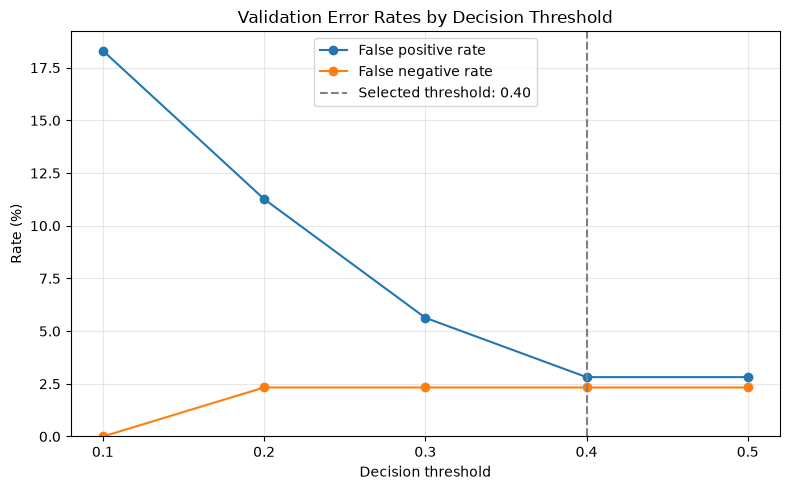

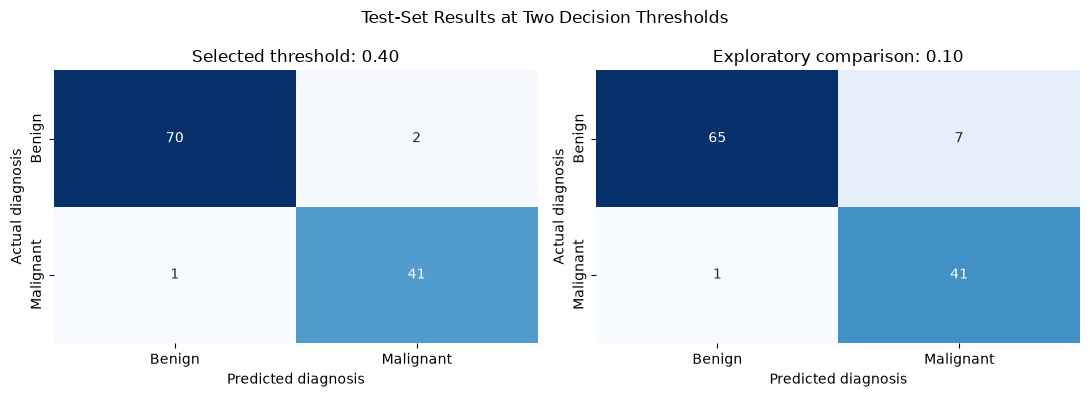

In [19]:
# Plot validation false positive and false negative rates
validation_plot = threshold_comparison.sort_values("Threshold")

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    validation_plot["Threshold"],
    validation_plot["False positive rate (%)"],
    marker="o",
    label="False positive rate",
)

ax.plot(
    validation_plot["Threshold"],
    validation_plot["False negative rate (%)"],
    marker="o",
    label="False negative rate",
)

# Mark the threshold selected using validation results
ax.axvline(
    x=0.40,
    color="gray",
    linestyle="--",
    label="Selected threshold: 0.40",
)

ax.set_title("Validation Error Rates by Decision Threshold")
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Rate (%)")
ax.set_xticks(validation_plot["Threshold"])
ax.set_ylim(bottom=0)
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()


# Compare test-set confusion matrices at thresholds 0.40 and 0.10
confusion_040 = confusion_matrix(
    y_test, test_predictions, labels=[0, 1]
)

confusion_010 = confusion_matrix(
    y_test, predictions_010_test, labels=[0, 1]
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.heatmap(
    confusion_040,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"],
    ax=axes[0],
)
axes[0].set_title("Selected threshold: 0.40")
axes[0].set_xlabel("Predicted diagnosis")
axes[0].set_ylabel("Actual diagnosis")

sns.heatmap(
    confusion_010,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"],
    ax=axes[1],
)
axes[1].set_title("Exploratory comparison: 0.10")
axes[1].set_xlabel("Predicted diagnosis")
axes[1].set_ylabel("Actual diagnosis")

fig.suptitle("Test-Set Results at Two Decision Thresholds")
plt.tight_layout()
plt.show()